<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/CO2-Assignment2/CO2_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITA06 – Machine Learning Assignment 2 (CO2)

**Complete executable notebook for Q1–Q7**

This notebook contains the calculations, custom perceptron, NumPy backpropagation implementation, synthetic data generator, neural-network experiments, validation-based selection, visualisations and final redesign comparison.

### Environment
Required packages: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and a standard Python 3 Jupyter kernel. No automatic-differentiation library is used for the assessed backpropagation calculation. The multilayer perceptrons for Q3–Q7 are trained with NumPy code in this notebook.

### How to run
Run cells from top to bottom. Generated results and plots are saved in an `a2_outputs` folder in the current working directory. The 1,000-row two-moons dataset is generated inside the notebook with a fixed random seed, so no additional dataset download is needed.

**Reproducibility:** data generator seed = 42; Q3 XOR initialisation seed = 1; Q4 seeds = 11, 22, 33; Q5 sample seed = 2026; Q6 seeds = 61 and 62. Training and validation partitions are fixed across relevant experiments.

## 0. Imports and shared utilities

In [1]:
import os, json, time, math, random
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

OUT=os.path.join(os.getcwd(),'a2_outputs'); FIG=os.path.join(OUT,'figures'); os.makedirs(FIG,exist_ok=True)
def sigmoid(z): return 1/(1+np.exp(-np.clip(z,-40,40)))
def bce(y,p):
 p=np.clip(p,1e-10,1-1e-10); return float(-np.mean(y*np.log(p)+(1-y)*np.log(1-p)))
def count_params(widths):
 dims=[2]+list(widths)+[1]; return sum(dims[i]*dims[i+1]+dims[i+1] for i in range(len(dims)-1))


## Q1. Neural-network representation and manual forward pass

The binary label is 0 for Acceptable and 1 for Defective. Three sensor features are standardised using training-only statistics. The hidden network is included to model nonlinear relationships between measurements.

In [2]:
# Q1
q1={'input_features':['Surface roughness','Dimensional deviation','Vibration level'],
'preprocessing':'Fit standardization parameters on training data only; impute missing values with training medians; inspect outliers and physically justify any clipping.',
'linear':{'layers':[3,1],'parameters':4,'equations':'z = x1*w1 + x2*w2 + x3*w3 + b; p = sigmoid(z)'},
'hidden':{'layers':[3,4,1],'parameters':21,'equations':'h = ReLU(xW1+b1); p = sigmoid(hW2+b2)'},
'manual':{'x':[0.5,-0.2,1.0],'w':[0.4,-0.3,0.2],'b':-0.1,'threshold':0.5}}
q1['manual']['z']=float(np.dot(q1['manual']['x'],q1['manual']['w'])+q1['manual']['b']); q1['manual']['p']=float(sigmoid(q1['manual']['z']));q1['manual']['class']=int(q1['manual']['p']>=.5)


## Q2. Perceptron learning and representational limitation

The code below uses a step activation with threshold 0.5, zero initial weights and bias, and the online perceptron update rule. It trains once on AND and separately on XOR at two learning rates.

In [3]:
# Q2 perceptron
X_logic=np.array([[0,0],[0,1],[1,0],[1,1]],float); y_and=np.array([0,0,0,1]);y_xor=np.array([0,1,1,0])
def train_perceptron(y,lr=.1,epochs=30,threshold=.5):
 w=np.zeros(2);b0=0.;init={'w':w.tolist(),'b':b0};pred0=(X_logic@w+b0>=threshold).astype(int).tolist(); rows=[];updates=[]
 for ep in range(1,epochs+1):
  errn=0; ups=[]
  for i,(x,t) in enumerate(zip(X_logic,y)):
   net=float(x@w+b0);pred=int(net>=threshold);e=int(t-pred)
   if e:
    ow=w.copy();ob=b0;w=w+lr*e*x;b0=b0+lr*e;errn+=1
    ups.append({'row':i,'x':x.tolist(),'target':int(t),'prediction_before':pred,'old_w':ow.tolist(),'old_b':ob,'new_w':w.tolist(),'new_b':float(b0)})
  pp=(X_logic@w+b0>=threshold).astype(int)
  rows.append({'epoch':ep,'mistakes':errn,'predictions':pp.tolist(),'weights':w.tolist(),'bias':float(b0)})
  updates.extend(ups)
  if errn==0:break
 return {'initial':init,'predictions_before':pred0,'updates':updates,'epochs':rows,'weights_final':w.tolist(),'bias_final':float(b0),'predictions_final':pp.tolist(),'converged':bool(np.array_equal(pp,y)),'epochs_run':len(rows)}
q2_and=train_perceptron(y_and,.1);q2_xor={str(l):train_perceptron(y_xor,l,30) for l in [.1,.5]}


## Q3. Multilayer perceptron and backpropagation

The 2–2–1 network uses sigmoid activations and binary cross-entropy. The gradients are computed explicitly with NumPy. The finite-difference test checks one analytical gradient, and the same network is trained on all four XOR input rows.

In [4]:
# Q3 manual calculations
x_m=np.array([1.,0.]); y_m=1.;eta=.1;W1=np.array([[.1,.2],[.3,.4]]);b1=np.array([.1,-.1]);W2=np.array([[.2],[-.3]]);b2=np.array([.05])
z1=x_m@W1+b1;h=sigmoid(z1);z2=float((h@W2+b2)[0]);p=float(sigmoid(z2));loss=float(-y_m*np.log(p)-(1-y_m)*np.log(1-p));d2=p-y_m;gW2=h.reshape(-1,1)*d2;gb2=np.array([d2]);dh=W2.ravel()*d2;d1=dh*h*(1-h);gW1=np.outer(x_m,d1);gb1=d1.copy()
q3_manual={'x':x_m.tolist(),'target':y_m,'learning_rate':eta,'W1_initial':W1.tolist(),'b1_initial':b1.tolist(),'W2_initial':W2.tolist(),'b2_initial':b2.tolist(),'z_hidden':z1.tolist(),'hidden_activation':h.tolist(),'z_output':z2,'prediction':p,'binary_cross_entropy':loss,'delta_output':float(d2),'gradient_W2':gW2.tolist(),'gradient_b2':gb2.tolist(),'delta_hidden':d1.tolist(),'gradient_W1':gW1.tolist(),'gradient_b1':gb1.tolist(),'W1_updated':(W1-eta*gW1).tolist(),'b1_updated':(b1-eta*gb1).tolist(),'W2_updated':(W2-eta*gW2).tolist(),'b2_updated':(b2-eta*gb2).tolist()}
# finite difference gradient W1[0,0]
def fwd_params(X,pa):
 h=sigmoid(X@pa['W1']+pa['b1']);p=sigmoid(h@pa['W2']+pa['b2']);return h,p
def loss_one(pa):
 _,pp=fwd_params(x_m.reshape(1,-1),pa);return -np.log(np.clip(pp[0,0],1e-10,1))
pa={'W1':W1.copy(),'b1':b1.copy(),'W2':W2.copy(),'b2':b2.copy()};h1,p1=fwd_params(x_m.reshape(1,-1),pa);dout=p1-1;gh=dout@pa['W2'].T;dhidden=gh*h1*(1-h1);analytic=float((x_m.reshape(1,-1).T@dhidden)[0,0]);e=1e-5;pa1={k:v.copy() for k,v in pa.items()};pa1['W1'][0,0]+=e;lp=loss_one(pa1);pa1['W1'][0,0]-=2*e;lm=loss_one(pa1);numeric=(lp-lm)/(2*e)
q3_fd={'parameter':'W1[0,0]','analytical_gradient':analytic,'finite_difference_gradient':float(numeric),'absolute_error':float(abs(analytic-numeric))}
# train xor 2-2-1 with full batch Adam
def mlp_train_xor(seed,lr=.05,steps=20000):
 rng=np.random.default_rng(seed); pars={'W1':rng.normal(0,1.5,(2,2)),'b1':rng.normal(0,.1,2),'W2':rng.normal(0,1.5,(2,1)),'b2':np.zeros(1)}
 m={k:np.zeros_like(v) for k,v in pars.items()};v={k:np.zeros_like(vv) for k,vv in pars.items()};losses=[];Y=y_xor.reshape(-1,1).astype(float)
 for t in range(1,steps+1):
  hh,pp=fwd_params(X_logic,pars); dz2=(pp-Y)/4; gw2=hh.T@dz2;gb2=dz2.sum(0);dh=dz2@pars['W2'].T;dz1=dh*hh*(1-hh);gw1=X_logic.T@dz1;gb1=dz1.sum(0);gr={'W1':gw1,'b1':gb1,'W2':gw2,'b2':gb2}
  for k in pars:
   m[k]=.9*m[k]+.1*gr[k];v[k]=.999*v[k]+.001*gr[k]**2;mh=m[k]/(1-.9**t);vh=v[k]/(1-.999**t);pars[k]-=lr*mh/(np.sqrt(vh)+1e-8)
  if t%20==0 or t==1:
   _,pp2=fwd_params(X_logic,pars);ls=bce(Y,pp2);losses.append((t,ls))
   if t>1000 and ls<.002:break
 _,pp=fwd_params(X_logic,pars)
 return pars,losses,pp
# choose seed achieving perfect XOR and low BCE
xor_trials=[]
for s in [1]:
 pars,lh,pp=mlp_train_xor(s,steps=5000)
 xor_trials.append((bce(y_xor.reshape(-1,1),pp),s,pars,lh,pp))
xor_trials.sort(key=lambda x:x[0]);xor_loss,xor_seed,xor_pars,xor_hist,xor_pred=xor_trials[0]
q3_xor={'seed':xor_seed,'optimizer':'custom Adam','learning_rate':.05,'epochs_run':int(xor_hist[-1][0]),'final_loss':float(xor_loss),'probabilities':xor_pred.ravel().tolist(),'predictions':(xor_pred.ravel()>=.5).astype(int).tolist(),'accuracy':float(np.mean((xor_pred.ravel()>=.5).astype(int)==y_xor)),'loss_history':xor_hist}


### Q4–Q7 shared NumPy neural-network implementation

This is a from-scratch dense MLP implementation supporting ReLU hidden layers, sigmoid output, mini-batch SGD, momentum, Adam, L2 penalties, dropout masks, validation checkpointing and optional early stopping.

In [5]:
# NumPy dense MLP training for Q4-Q7
class NumpyMLP:
 def __init__(self,widths,seed=0,dropout=0.):
  rng=np.random.default_rng(seed);dims=[2]+list(widths)+[1];self.W=[];self.b=[]
  for i in range(len(dims)-1):
   scale=np.sqrt(2/dims[i]) if i<len(dims)-2 else np.sqrt(1/dims[i])
   self.W.append(rng.normal(0,scale,(dims[i],dims[i+1])));self.b.append(np.zeros((1,dims[i+1])))
  self.dropout=dropout
 def forward(self,X,training=False,rng=None):
  A=X;acts=[A];zs=[];masks=[]
  for i in range(len(self.W)-1):
   z=A@self.W[i]+self.b[i];a=np.maximum(0,z);mask=None
   if training and self.dropout>0:
    mask=(rng.random(a.shape)>=self.dropout).astype(float)/(1-self.dropout);a=a*mask
   zs.append(z);masks.append(mask);A=a;acts.append(A)
  logits=A@self.W[-1]+self.b[-1];probs=sigmoid(logits);return probs,acts,zs,masks
 def predict_prob(self,X):return self.forward(X,False)[0].ravel()
 def param_count(self):return int(sum(w.size+b.size for w,b in zip(self.W,self.b)))
 def loss(self,X,y,l2=0):
  p=self.predict_prob(X);return bce(y.reshape(-1,1),p.reshape(-1,1))+l2*.5*sum(float((w*w).sum()) for w in self.W)
 def grads(self,X,y,l2=0,rng=None):
  P,acts,zs,masks=self.forward(X,True,rng);m=len(X);d=(P-y.reshape(-1,1))/m;gW=[None]*len(self.W);gb=[None]*len(self.b)
  gW[-1]=acts[-1].T@d+l2*self.W[-1];gb[-1]=d.sum(0,keepdims=True)
  da=d@self.W[-1].T
  for i in range(len(self.W)-2,-1,-1):
   if masks[i] is not None: da=da*masks[i]
   dz=da*(zs[i]>0);gW[i]=acts[i].T@dz+l2*self.W[i];gb[i]=dz.sum(0,keepdims=True);da=dz@self.W[i].T
  return gW,gb

def train_numpy(widths, Xtr,ytr,Xva,yva,seed=1,lr=.01,batch=32,optimizer='adam',momentum=.9,l2=0.,dropout=0.,epochs=150,patience=None):
 rng=np.random.default_rng(seed);model=NumpyMLP(widths,seed,dropout);mW=[np.zeros_like(w) for w in model.W];vW=[np.zeros_like(w) for w in model.W];mb=[np.zeros_like(b) for b in model.b];vb=[np.zeros_like(b) for b in model.b];velW=[np.zeros_like(w) for w in model.W];velb=[np.zeros_like(b) for b in model.b];t=0
 H={'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]};best=float('inf');best_epoch=0;best_params=None;wait=0;start=time.perf_counter()
 for ep in range(1,epochs+1):
  order=rng.permutation(len(Xtr))
  for st in range(0,len(Xtr),batch):
   ix=order[st:st+batch];gW,gb=model.grads(Xtr[ix],ytr[ix],l2,rng);t+=1
   for i in range(len(model.W)):
    if optimizer=='sgd': model.W[i]-=lr*gW[i];model.b[i]-=lr*gb[i]
    elif optimizer=='momentum':
     velW[i]=momentum*velW[i]+gW[i];velb[i]=momentum*velb[i]+gb[i];model.W[i]-=lr*velW[i];model.b[i]-=lr*velb[i]
    elif optimizer=='adam':
     mW[i]=.9*mW[i]+.1*gW[i];vW[i]=.999*vW[i]+.001*gW[i]**2;mb[i]=.9*mb[i]+.1*gb[i];vb[i]=.999*vb[i]+.001*gb[i]**2
     model.W[i]-=lr*(mW[i]/(1-.9**t))/(np.sqrt(vW[i]/(1-.999**t))+1e-8);model.b[i]-=lr*(mb[i]/(1-.9**t))/(np.sqrt(vb[i]/(1-.999**t))+1e-8)
    else:raise ValueError(optimizer)
  pl=model.predict_prob(Xtr);pv=model.predict_prob(Xva);tl=model.loss(Xtr,ytr,l2);vl=model.loss(Xva,yva,l2)
  ta=float(np.mean((pl>=.5)==ytr));va=float(np.mean((pv>=.5)==yva))
  H['train_loss'].append(tl);H['val_loss'].append(vl);H['train_acc'].append(ta);H['val_acc'].append(va)
  if vl<best-1e-8:
   best=vl;best_epoch=ep;best_params=([w.copy() for w in model.W],[b.copy() for b in model.b]);wait=0
  else:wait+=1
  if patience is not None and wait>=patience:break
 elapsed=time.perf_counter()-start
 final_params=([w.copy() for w in model.W],[b.copy() for b in model.b]);final_train_acc=H['train_acc'][-1];final_val_acc=H['val_acc'][-1];final_train_loss=H['train_loss'][-1];final_val_loss=H['val_loss'][-1]
 # restore best val checkpoint for downstream eval; keep final metrics in history
 model.W=[w.copy() for w in best_params[0]];model.b=[b.copy() for b in best_params[1]]
 return {'model':model,'history':H,'best_epoch':best_epoch,'best_val_loss':best,'best_train_acc':H['train_acc'][best_epoch-1],'best_val_acc':H['val_acc'][best_epoch-1],'best_train_loss':H['train_loss'][best_epoch-1],'best_val_loss':H['val_loss'][best_epoch-1],'epochs_run':len(H['train_loss']),'time':elapsed,'params':model.param_count(),'final_train_acc':final_train_acc,'final_val_acc':final_val_acc,'final_train_loss':final_train_loss,'final_val_loss':final_val_loss}


## Q3 validation: loss curve and Q4 dataset generation

The two-moons data contains 1,000 synthetic observations and two numerical features. It is split into 600 training, 200 validation and 200 test observations. Standardisation is fit on training data only.

In [6]:
# Q3 loss curve
plt.figure(figsize=(6.5,4));plt.plot([t for t,_ in xor_hist],[v for _,v in xor_hist]);plt.xlabel('Training step');plt.ylabel('Binary cross-entropy');plt.title('Q3 - XOR MLP training loss');plt.tight_layout();plt.savefig(os.path.join(FIG,'q3_xor_loss.png'),dpi=170);plt.close()

# create fixed 1000-record two moons data and partitions
X_all,y_all=make_moons(n_samples=1000,noise=.25,random_state=42)
X_tmp,X_test,y_tmp,y_test=train_test_split(X_all,y_all,test_size=.20,random_state=42,stratify=y_all)
X_train,X_val,y_train,y_val=train_test_split(X_tmp,y_tmp,test_size=.25,random_state=42,stratify=y_tmp)
sc=StandardScaler().fit(X_train);Xtr=sc.transform(X_train);Xva=sc.transform(X_val);Xte=sc.transform(X_test)
pd.DataFrame({'feature_1':X_all[:,0],'feature_2':X_all[:,1],'AtRisk':y_all}).to_csv(os.path.join(OUT,'synthetic_two_moons_1000.csv'),index=False)


## Q4. One hidden layer versus three hidden layers

The shallow model has 32 hidden units. The deep model has three hidden layers with 16 units each. Both use the same split, Adam, learning rate 0.01, batch size 32 and a maximum of 100 epochs. Three initialisation seeds are used. Architecture selection uses mean validation loss; only the selected architecture is then evaluated on the held-out test set.

In [7]:
# Q4 three seeds each; model architectures and learning curves
q4={};q4_models={};q4_seed_models={}
for name,widths in [('shallow',(32,)),('deep',(16,16,16))]:
 print('Q4 start',name,flush=True)
 results=[]
 for seed in [11,22,33]:
  rr=train_numpy(widths,Xtr,y_train,Xva,y_val,seed=seed,lr=.01,batch=32,optimizer='adam',epochs=100)
  results.append({'seed':seed,'params':rr['params'],'best_epoch':rr['best_epoch'],'best_val_loss':rr['best_val_loss'],'best_val_accuracy':rr['best_val_acc'],'train_accuracy_at_best':rr['best_train_acc'],'training_time_sec':rr['time'],'history':rr['history']})
  q4_seed_models.setdefault(name,[]).append(rr['model'])
  if seed==11:q4_models[name]=rr['model']
 q4[name]={'widths':list(widths),'parameters':count_params(widths),'runs':results,'val_accuracy_mean':float(np.mean([r['best_val_accuracy'] for r in results])),'val_accuracy_sd':float(np.std([r['best_val_accuracy'] for r in results],ddof=1)),'training_time_mean':float(np.mean([r['training_time_sec'] for r in results]))}
# Select architecture using validation loss only, then evaluate the held-out test partition
q4_selected_name=min(q4,key=lambda nm:np.mean([r['best_val_loss'] for r in q4[nm]['runs']]))
q4_selected_test=[float(np.mean((m.predict_prob(Xte)>=.5)==y_test)) for m in q4_seed_models[q4_selected_name]]
q4_selected={'architecture':q4_selected_name,'mean_validation_loss':float(np.mean([r['best_val_loss'] for r in q4[q4_selected_name]['runs']])),'test_accuracy_by_seed':q4_selected_test,'test_accuracy_mean':float(np.mean(q4_selected_test)),'test_accuracy_sd':float(np.std(q4_selected_test,ddof=1))}
# q4 plot mean first seed history
plt.figure(figsize=(7,4.5))
for name,lab in [('shallow','One hidden layer (32)'),('deep','Three hidden layers (16 each)')]:
 h=q4[name]['runs'][0]['history'];plt.plot(h['train_loss'],label=lab+' train');plt.plot(h['val_loss'],'--',label=lab+' validation')
plt.xlabel('Epoch');plt.ylabel('Binary cross-entropy');plt.title('Q4 - Learning curves');plt.legend(fontsize=8);plt.tight_layout();plt.savefig(os.path.join(FIG,'q4_learning_curves.png'),dpi=170);plt.close()
def draw_boundary(ax,model,title):
 xx,yy=np.meshgrid(np.linspace(X_all[:,0].min()-.5,X_all[:,0].max()+.5,250),np.linspace(X_all[:,1].min()-.5,X_all[:,1].max()+.5,250));gg=sc.transform(np.c_[xx.ravel(),yy.ravel()]);zz=model.predict_prob(gg).reshape(xx.shape)
 ax.contourf(xx,yy,zz,levels=[0,.5,1],alpha=.25);ax.contour(xx,yy,zz,levels=[.5],linewidths=1.2);ax.scatter(X_train[:,0],X_train[:,1],c=y_train,s=8,edgecolors='k',linewidths=.1);ax.set_title(title);ax.set_xlabel('Feature 1');ax.set_ylabel('Feature 2')
fig,axs=plt.subplots(1,2,figsize=(10,4));draw_boundary(axs[0],q4_models['shallow'],'Shallow: 32 units');draw_boundary(axs[1],q4_models['deep'],'Deep: 16-16-16');plt.tight_layout();plt.savefig(os.path.join(FIG,'q4_decision_boundaries.png'),dpi=170);plt.close()


Q4 start shallow
Q4 start deep


## Q5. Overfitting and regularization

Only 100 labelled observations are sampled from the original training partition. The scaler is refit on those 100 training rows only. The validation and test partitions remain separate. The large 128–128–64 model is compared under baseline, L2, dropout and early stopping settings. The final method is selected using validation loss before test evaluation.

In [8]:
# Q5: 100 train observations, larger 128-128-64 model
rng=np.random.default_rng(2026);ix100=np.sort(rng.choice(len(X_train),100,replace=False));sc_small=StandardScaler().fit(X_train[ix100]);X100=sc_small.transform(X_train[ix100]);Xva_small=sc_small.transform(X_val);Xte_small=sc_small.transform(X_test);y100=y_train[ix100]
q5={};q5_hist={};q5_models={}
methods=[('baseline',0.,0.,None),('L2',.01,0.,None),('dropout',0.,.4,None),('early_stopping',0.,0.,20)]
for name,l2,drop,pat in methods:
 print('Q5 start',name,flush=True)
 rr=train_numpy((128,128,64),X100,y100,Xva_small,y_val,seed=44,lr=.01,batch=16,optimizer='adam',l2=l2,dropout=drop,epochs=140,patience=pat)
 q5[name]={k:rr[k] for k in ['best_epoch','best_val_loss','best_val_acc','best_train_acc','epochs_run','time','params','final_train_acc','final_val_acc','final_train_loss','final_val_loss']};q5_hist[name]=rr['history'];q5_models[name]=rr['model']
q5_selected_name=min(q5,key=lambda nm:q5[nm]['best_val_loss'])
q5_selected_test=float(np.mean((q5_models[q5_selected_name].predict_prob(Xte_small)>=.5)==y_test))
q5_selected={'method':q5_selected_name,'validation_loss':q5[q5_selected_name]['best_val_loss'],'validation_accuracy':q5[q5_selected_name]['best_val_acc'],'test_accuracy':q5_selected_test}
plt.figure(figsize=(7,4.5))
for name in q5:
 plt.plot(q5_hist[name]['val_loss'],label=name)
plt.xlabel('Epoch');plt.ylabel('Validation BCE');plt.title('Q5 - Validation loss under regularization');plt.legend();plt.tight_layout();plt.savefig(os.path.join(FIG,'q5_regularization.png'),dpi=170);plt.close()
plt.figure(figsize=(7,4.5))
for name in q5:
 plt.plot(q5_hist[name]['train_acc'],label=name+' train');plt.plot(q5_hist[name]['val_acc'],'--',label=name+' val')
plt.xlabel('Epoch');plt.ylabel('Accuracy');plt.title('Q5 - Accuracy and generalization gap');plt.legend(fontsize=7,ncol=2);plt.tight_layout();plt.savefig(os.path.join(FIG,'q5_accuracy.png'),dpi=170);plt.close()


Q5 start baseline
Q5 start L2
Q5 start dropout
Q5 start early_stopping


## Q6. Twelve-run hyperparameter and optimizer search

The candidate runs change learning rate, batch size, hidden width or optimizer in controlled groups. Every candidate uses the same training/validation partitions and an 80-epoch maximum. The test set is evaluated only after choosing the lowest-validation-loss configuration.

In [9]:
# Q6: 12 runs. same partitions; one-hidden-layer widths
configs=[
(1,'adam',.001,32,32,61,'learning rate'),(2,'adam',.01,32,32,61,'learning rate'),(3,'adam',.05,32,32,61,'learning rate'),
(4,'adam',.01,16,32,61,'batch size'),(5,'adam',.01,64,32,61,'batch size'),(6,'adam',.01,32,16,61,'hidden width'),(7,'adam',.01,32,64,61,'hidden width'),
(8,'sgd',.01,32,32,61,'optimizer'),(9,'sgd',.05,32,32,61,'optimizer'),(10,'momentum',.01,32,32,61,'momentum'),(11,'momentum',.05,32,32,61,'momentum'),(12,'adam',.01,32,32,62,'repeat seed')]
q6=[]
for rid,opt,lr,bs,width,seed,factor in configs:
 print('Q6 start',rid,flush=True)
 rr=train_numpy((width,),Xtr,y_train,Xva,y_val,seed=seed,lr=lr,batch=bs,optimizer=opt,epochs=80)
 q6.append({'run':rid,'optimizer':opt,'learning_rate':lr,'batch_size':bs,'hidden_width':width,'seed':seed,'factor':factor,'parameters':rr['params'],'best_epoch':rr['best_epoch'],'best_validation_loss':rr['best_val_loss'],'best_validation_accuracy':rr['best_val_acc'],'train_accuracy_at_best':rr['best_train_acc'],'training_time_sec':rr['time']})
q6_selected=min(q6,key=lambda r:r['best_validation_loss'])
q6_final=train_numpy((q6_selected['hidden_width'],),Xtr,y_train,Xva,y_val,seed=q6_selected['seed'],lr=q6_selected['learning_rate'],batch=q6_selected['batch_size'],optimizer=q6_selected['optimizer'],epochs=80)
q6_selected['final_test_accuracy']=float(np.mean((q6_final['model'].predict_prob(Xte)>=.5)==y_test))
pd.DataFrame(q6).to_csv(os.path.join(OUT,'q6_12_run_results.csv'),index=False)


Q6 start 1
Q6 start 2
Q6 start 3
Q6 start 4
Q6 start 5
Q6 start 6
Q6 start 7
Q6 start 8
Q6 start 9
Q6 start 10
Q6 start 11
Q6 start 12


## Q7. Day-4 redesign: replace the linear XOR classifier

The original perceptron is limited by its linear decision boundary, not by the learning rate. The revised model uses two nonlinear sigmoid hidden units and one sigmoid output. It is compared on the same four XOR truth-table rows.

In [10]:
# Q7 redesigned XOR model: Q3 MLP is the prototype; compare perceptron and MLP
q7={'baseline_perceptron':{'parameters':3,'converged':q2_xor['0.1']['converged'],'final_predictions':q2_xor['0.1']['predictions_final'],'epochs_run':q2_xor['0.1']['epochs_run']},
'redesigned_mlp':{'parameters':9,'seed':xor_seed,'final_loss':float(xor_loss),'probabilities':xor_pred.ravel().tolist(),'predictions':(xor_pred.ravel()>=.5).astype(int).tolist(),'accuracy':float(np.mean((xor_pred.ravel()>=.5).astype(int)==y_xor)),'epochs_run':int(xor_hist[-1][0])},
'objective':'Replace the linear XOR classifier with a minimal nonlinear model that classifies all four XOR combinations correctly.',
'prediction':'The perceptron will not converge for XOR; a two-hidden-unit sigmoid MLP should fit the four truth-table rows.'}

results={'q1':q1,'q2':{'AND':q2_and,'XOR':q2_xor},'q3':{'manual':q3_manual,'finite_difference':q3_fd,'XOR_training':q3_xor},
'dataset':{'description':'Synthetic interleaving two-moons binary classification','generator':'sklearn.datasets.make_moons(n_samples=1000, noise=0.25, random_state=42)','n':1000,'features':2,'class_counts':np.bincount(y_all).tolist(),'noise':.25,'train':len(X_train),'validation':len(X_val),'test':len(X_test),'split_random_state':42,'scaler_fit_on':'training partition only'},
'q4':{'architectures':q4,'selected':q4_selected},'q5':{'methods':q5,'selected':q5_selected},'q6':{'runs':q6,'selected_by_validation_loss':q6_selected},'q7':q7,
'figures':{f:os.path.join(FIG,f) for f in os.listdir(FIG)}}
def conv(o):
 if isinstance(o,dict):return {k:conv(v) for k,v in o.items()}
 if isinstance(o,(list,tuple)):return [conv(v) for v in o]
 if isinstance(o,(np.integer,)):return int(o)
 if isinstance(o,(np.floating,)):return float(o)
 return o
with open(os.path.join(OUT,'results.json'),'w') as f:json.dump(conv(results),f,indent=2)
print('Q1 manual',q1['manual'])
print('Q2 AND converged/epochs/pred',q2_and['converged'],q2_and['epochs_run'],q2_and['predictions_final'])
print('Q2 XOR', {k:(v['converged'],v['predictions_final'],v['epochs_run']) for k,v in q2_xor.items()})
print('Q3 manual',q3_manual)
print('Q3 finite diff',q3_fd)
print('Q3 XOR',q3_xor)
print('Q4 architecture validation summary', {k:{x:v[x] for x in ['parameters','val_accuracy_mean','val_accuracy_sd','training_time_mean']} for k,v in q4.items()}, 'selected and test', q4_selected)
print('Q5',q5,'selected',q5_selected)
print('Q6 selected',q6_selected)
print('Q7',q7)
print('Saved',os.path.join(OUT,'results.json'))

Q1 manual {'x': [0.5, -0.2, 1.0], 'w': [0.4, -0.3, 0.2], 'b': -0.1, 'threshold': 0.5, 'z': 0.36, 'p': 0.5890404340586651, 'class': 1}
Q2 AND converged/epochs/pred True 3 [0, 0, 0, 1]
Q2 XOR {'0.1': (False, [1, 1, 0, 0], 30), '0.5': (False, [1, 1, 0, 0], 30)}
Q3 manual {'x': [1.0, 0.0], 'target': 1.0, 'learning_rate': 0.1, 'W1_initial': [[0.1, 0.2], [0.3, 0.4]], 'b1_initial': [0.1, -0.1], 'W2_initial': [[0.2], [-0.3]], 'b2_initial': [0.05], 'z_hidden': [0.2, 0.1], 'hidden_activation': [0.549833997312478, 0.52497918747894], 'z_output': 0.0024730432188136003, 'prediction': 0.5006182604895997, 'binary_cross_entropy': 0.6919114234431888, 'delta_output': -0.4993817395104003, 'gradient_W2': [[-0.27457705801986204], [-0.26216501984998963]], 'gradient_b2': [-0.4993817395104003], 'delta_hidden': [-0.024721051327700222, 0.03736015222312256], 'gradient_W1': [[-0.024721051327700222, 0.03736015222312256], [-0.0, 0.0]], 'gradient_b1': [-0.024721051327700222, 0.03736015222312256], 'W1_updated': [[0.10

## 10. Network diagrams, geometry plots and final figures

In [11]:
from matplotlib.patches import Circle, FancyArrowPatch

def draw_network(ax, layers, labels, title):
    xs=np.linspace(.12,.88,len(layers)); coords=[]
    for i,n in enumerate(layers):
        ys=np.linspace(.15,.85,n) if n>1 else np.array([.5]); lay=[]
        for j,y in enumerate(ys):
            xy=(xs[i],y);lay.append(xy)
            ax.add_patch(Circle(xy,.045,facecolor='white',edgecolor='black',linewidth=1.1,zorder=3))
            label=f'x{j+1}' if i==0 else ('ŷ' if i==len(layers)-1 else f'h{j+1}')
            ax.text(xy[0],xy[1],label,ha='center',va='center',fontsize=8)
        coords.append(lay)
    for i in range(len(layers)-1):
        for a in coords[i]:
            for b in coords[i+1]:
                ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-',linewidth=.65,color='0.35',zorder=1,shrinkA=8,shrinkB=8))
    for x,lbl in zip(xs,labels): ax.text(x,.04,lbl,ha='center',va='bottom',fontsize=8)
    ax.set_title(title,fontsize=10,fontweight='bold');ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis('off')

fig,axs=plt.subplots(1,2,figsize=(9,3.5))
draw_network(axs[0],[3,1],['3 input features','sigmoid output'],'Q1-A. No hidden layer (4 parameters)')
draw_network(axs[1],[3,4,1],['3 inputs','4 ReLU hidden units','sigmoid output'],'Q1-B. One hidden layer (21 parameters)')
plt.tight_layout();plt.savefig(os.path.join(FIG,'q1_architectures.png'),dpi=180,bbox_inches='tight');plt.close()

logic_points=np.array([[0,0],[0,1],[1,0],[1,1]])
fig,axs=plt.subplots(1,2,figsize=(9,3.8))
for ax,labs,title in [(axs[0],[0,0,0,1],'AND: linearly separable'),(axs[1],[0,1,1,0],'XOR: not linearly separable')]:
    for (x,y),lab in zip(logic_points,labs):
        ax.scatter(x,y,s=115,marker='o' if lab else 's',facecolors='black' if lab else 'white',edgecolors='black',linewidth=1.4,zorder=3)
        ax.text(x+.06,y+.05,str(lab),fontsize=9)
    ax.set_xlim(-.25,1.4);ax.set_ylim(-.25,1.35);ax.set_xticks([0,1]);ax.set_yticks([0,1]);ax.set_xlabel('Packaging complete');ax.set_ylabel('Quality check passed');ax.grid(True,alpha=.25);ax.set_title(title,fontsize=10,fontweight='bold')
x=np.linspace(.5,1.25,100);axs[0].plot(x,1.5-x,'k--',linewidth=1.3,label='x1 + x2 = 1.5');axs[0].legend(fontsize=7)
plt.tight_layout();plt.savefig(os.path.join(FIG,'q2_geometry.png'),dpi=180,bbox_inches='tight');plt.close()

fig,ax=plt.subplots(figsize=(7,3.8));draw_network(ax,[2,2,1],['2 binary inputs','2 sigmoid hidden units','1 sigmoid output'],'Q3/Q7: 2–2–1 MLP for XOR (9 parameters)');plt.tight_layout();plt.savefig(os.path.join(FIG,'q3_mlp_architecture.png'),dpi=180,bbox_inches='tight');plt.close()

fig,ax=plt.subplots(figsize=(8,4));run_ids=[row['run'] for row in q6];vloss=[row['best_validation_loss'] for row in q6]
ax.bar(run_ids,vloss,edgecolor='black',linewidth=.5);ax.set_xlabel('Candidate run');ax.set_ylabel('Best validation loss');ax.set_title('Q6: Validation loss across the 12-run search');ax.set_xticks(run_ids);ax.grid(axis='y',alpha=.25);plt.tight_layout();plt.savefig(os.path.join(FIG,'q6_validation_loss.png'),dpi=180);plt.close()

fig,ax=plt.subplots(figsize=(8,2.2));ax.axis('off')
boxes=[(.05,'XOR inputs\n(2 features)'),(.29,'Hidden layer\n2 sigmoid units'),(.57,'Output layer\n1 sigmoid unit'),(.82,'Decision\nthreshold 0.5')]
for x0,t in boxes: ax.text(x0,.5,t,ha='center',va='center',fontsize=9,bbox=dict(boxstyle='round,pad=.55',facecolor='white',edgecolor='black'))
for i in range(len(boxes)-1): ax.annotate('',xy=(boxes[i+1][0]-.075,.5),xytext=(boxes[i][0]+.075,.5),arrowprops=dict(arrowstyle='->',lw=1.2,color='black'))
ax.set_title('Q7: Revised nonlinear classification workflow',fontsize=10,fontweight='bold');plt.tight_layout();plt.savefig(os.path.join(FIG,'q7_redesign_workflow.png'),dpi=180,bbox_inches='tight');plt.close()

print('Saved figures:', sorted(os.listdir(FIG)))

Saved figures: ['q1_architectures.png', 'q2_geometry.png', 'q3_mlp_architecture.png', 'q3_xor_loss.png', 'q4_decision_boundaries.png', 'q4_learning_curves.png', 'q5_accuracy.png', 'q5_regularization.png', 'q6_validation_loss.png', 'q7_redesign_workflow.png']


## 11. Compact results summary and figure preview

The tables below report the selected results. More detailed epoch histories are retained in the variables created above and can be inspected or exported.

Q1 parameter counts: 4 and 21
Q2 AND: True 3 [0, 0, 0, 1]
Q2 XOR: {'0.1': (False, [1, 1, 0, 0]), '0.5': (False, [1, 1, 0, 0])}
Q3 finite-difference gradient check: {'parameter': 'W1[0,0]', 'analytical_gradient': -0.024721051327700222, 'finite_difference_gradient': -0.024721051333775886, 'absolute_error': 6.0756642772386016e-12}
Q3 XOR MLP accuracy/loss: 1.0 0.0019323486997135332
Q4 architecture selected on validation loss: {'architecture': 'shallow', 'mean_validation_loss': 0.16033324822963424, 'test_accuracy_by_seed': [0.975, 0.975, 0.98], 'test_accuracy_mean': 0.9766666666666666, 'test_accuracy_sd': 0.0028867513459481316}
Q5 regularizer selected on validation loss: {'method': 'dropout', 'validation_loss': 0.24306777678660133, 'validation_accuracy': 0.915, 'test_accuracy': 0.93}
Q6 selected configuration: {'run': 3, 'optimizer': 'adam', 'learning_rate': 0.05, 'batch_size': 32, 'hidden_width': 32, 'seed': 61, 'factor': 'learning rate', 'parameters': 129, 'best_epoch': 56, 'best_validat

,Question,Validation loss,Validation accuracy,Test accuracy
0,Q4 selected architecture,0.160333,0.918333,0.976667
1,Q5 selected regularizer,0.243068,0.915000,0.930000
2,Q6 selected optimizer config,0.146869,0.920000,0.970000


q1_architectures.png


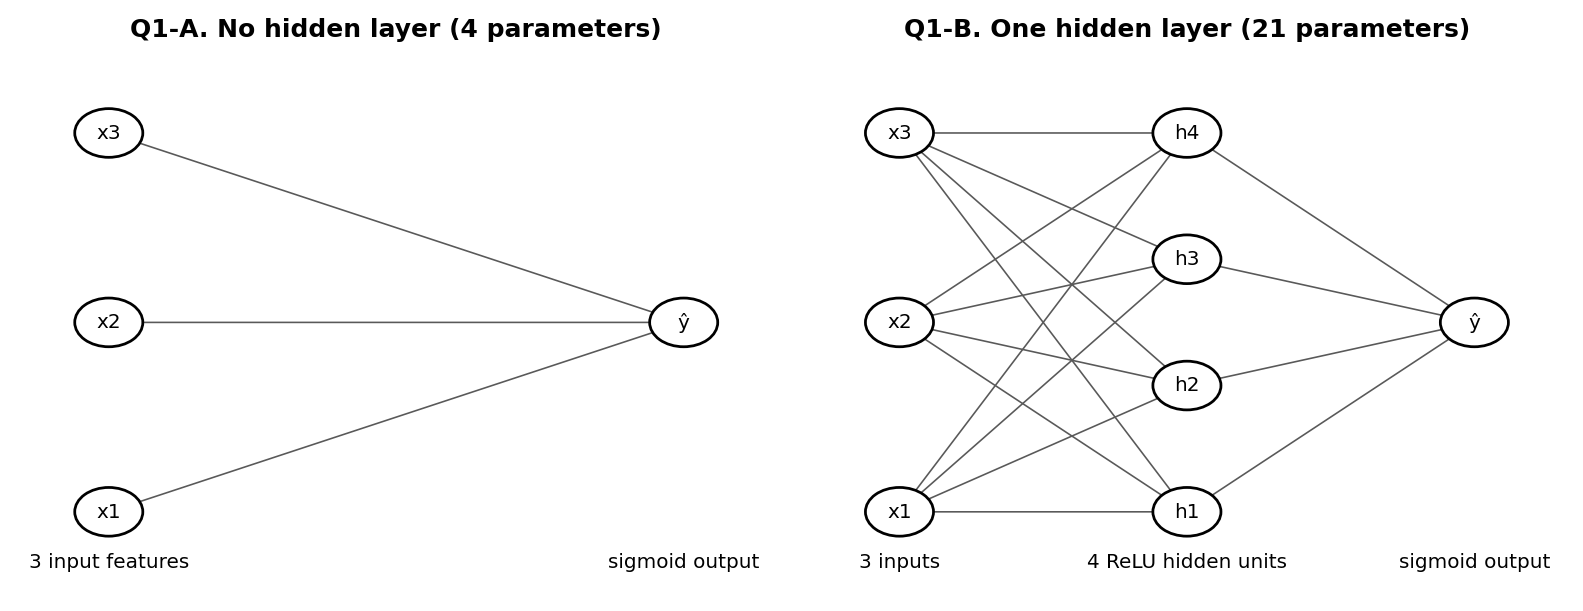

q2_geometry.png


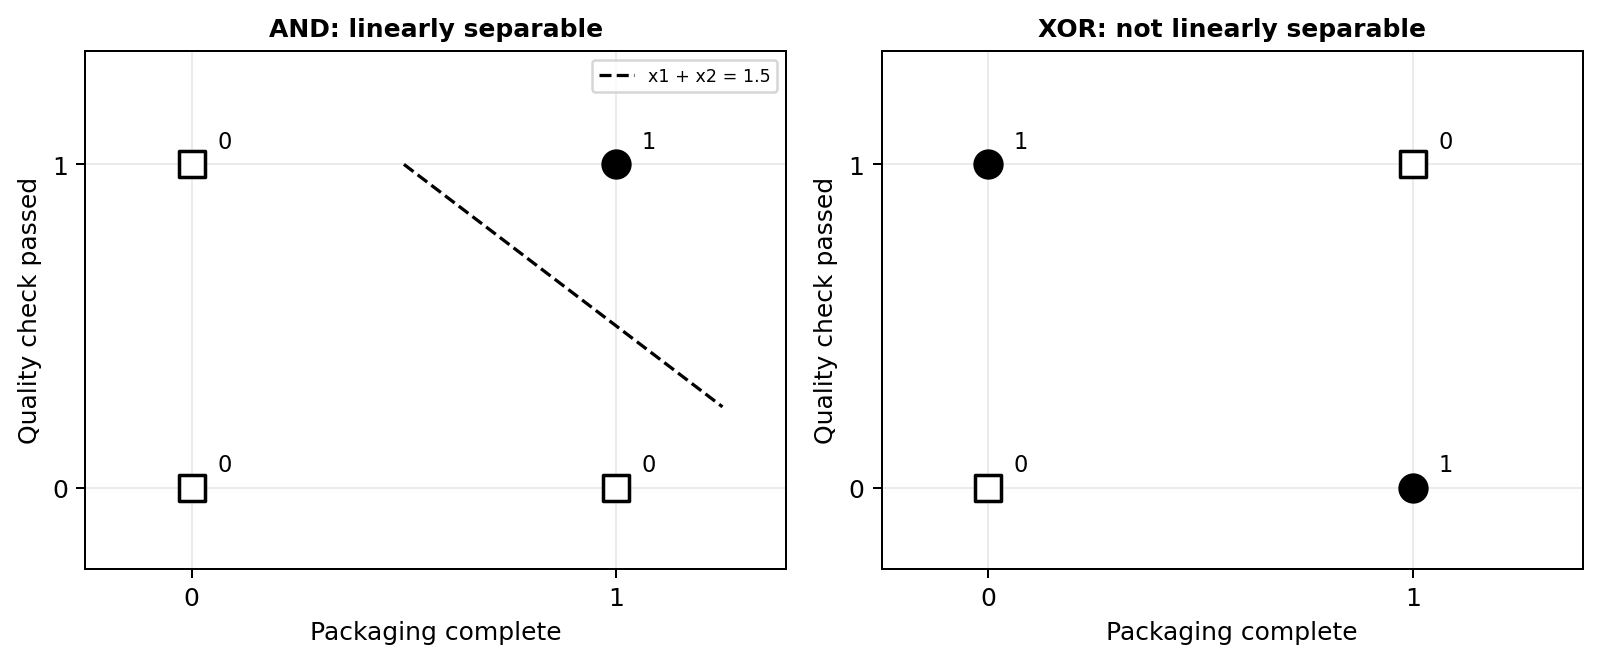

q3_mlp_architecture.png


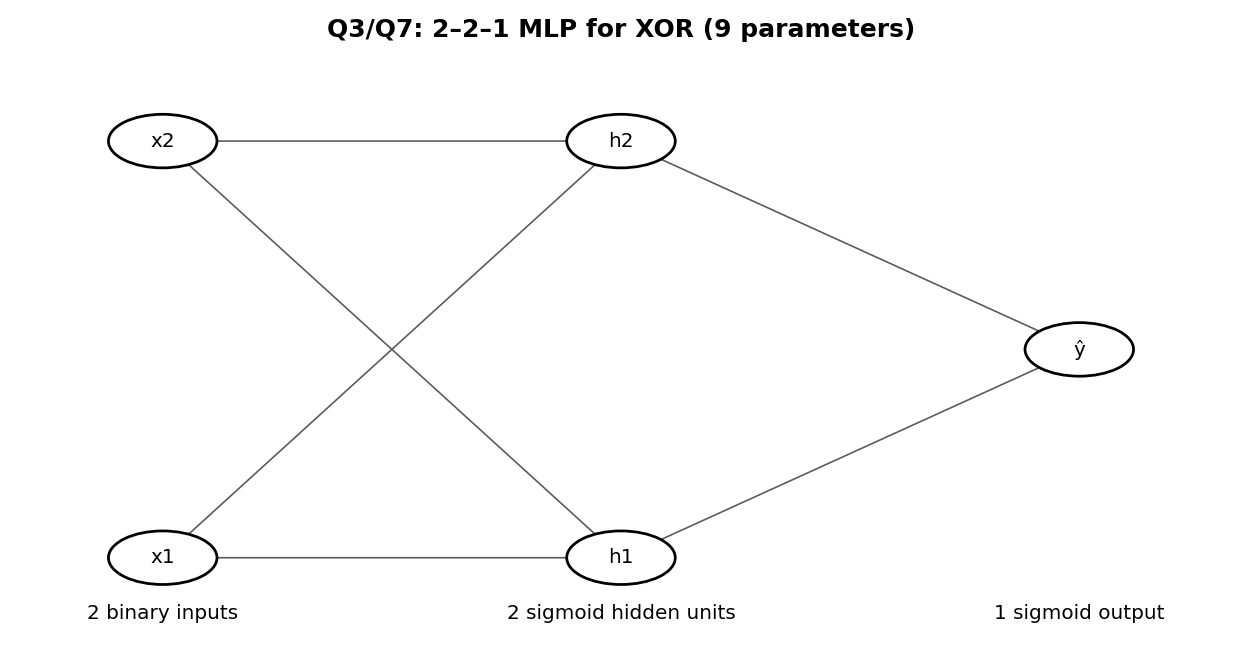

q3_xor_loss.png


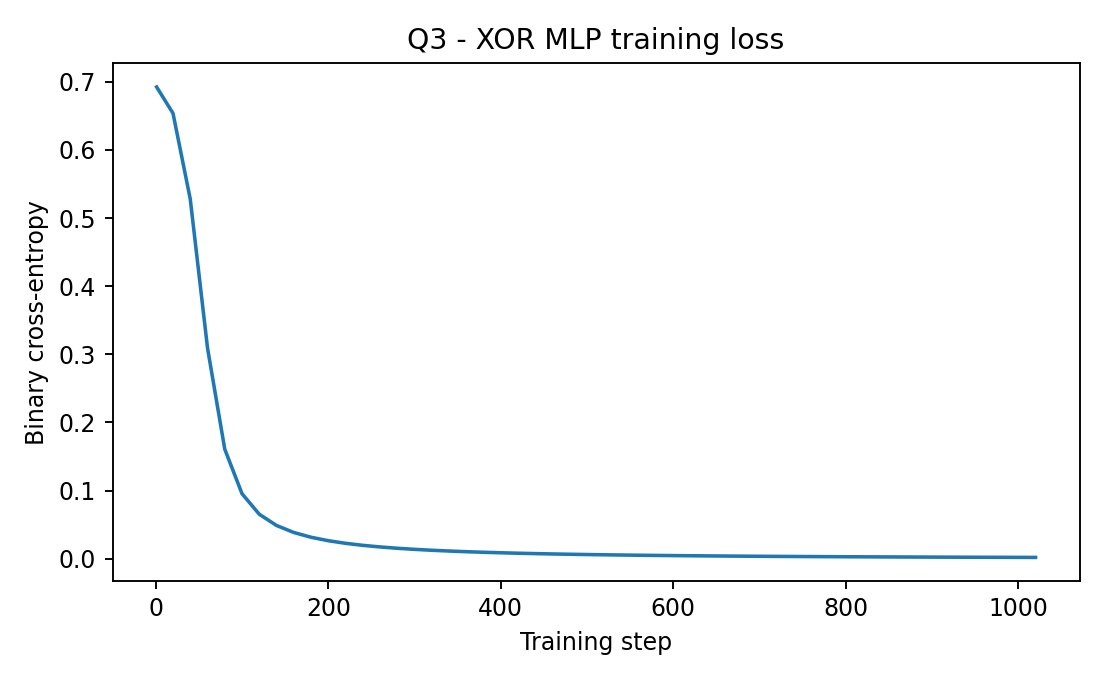

q4_decision_boundaries.png


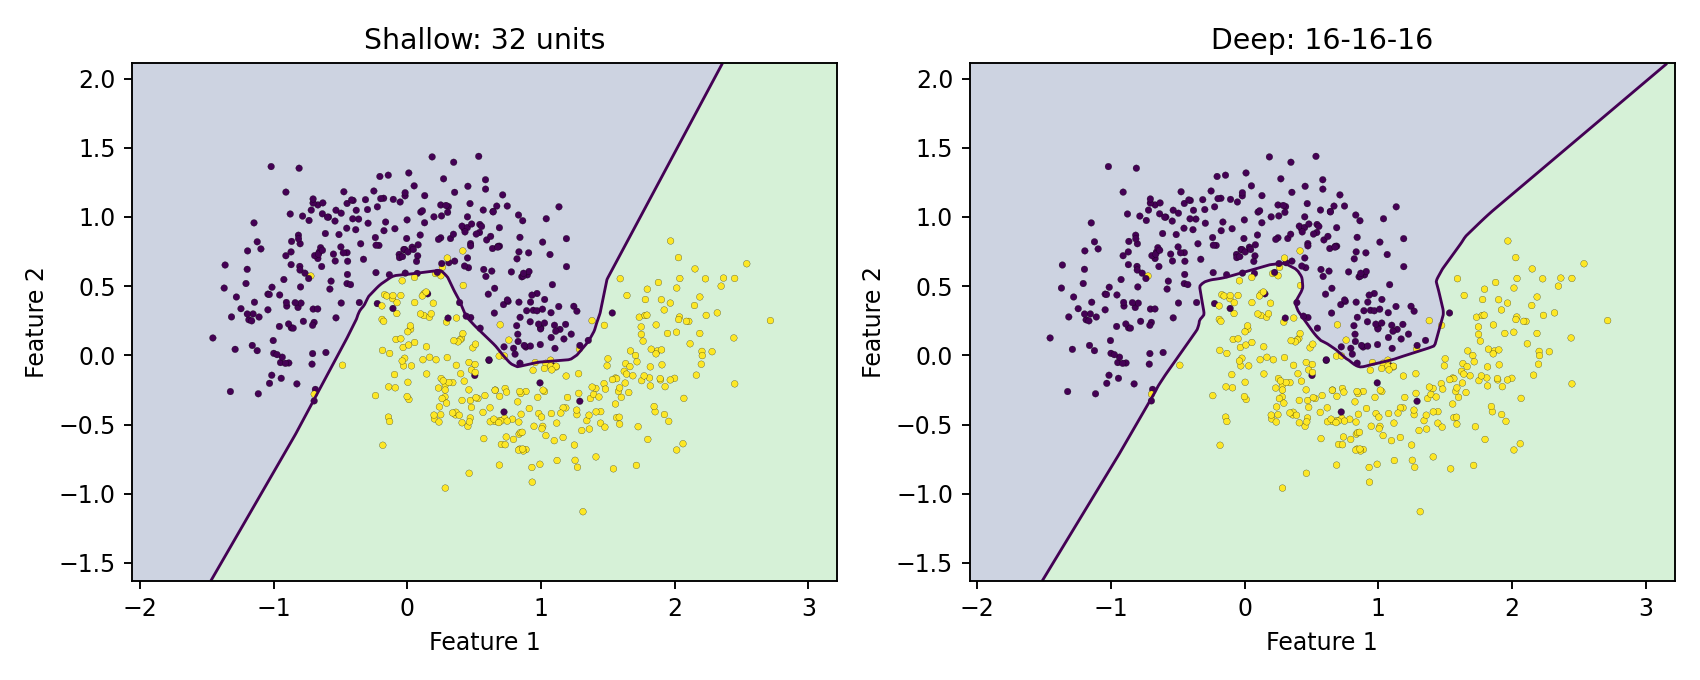

q4_learning_curves.png


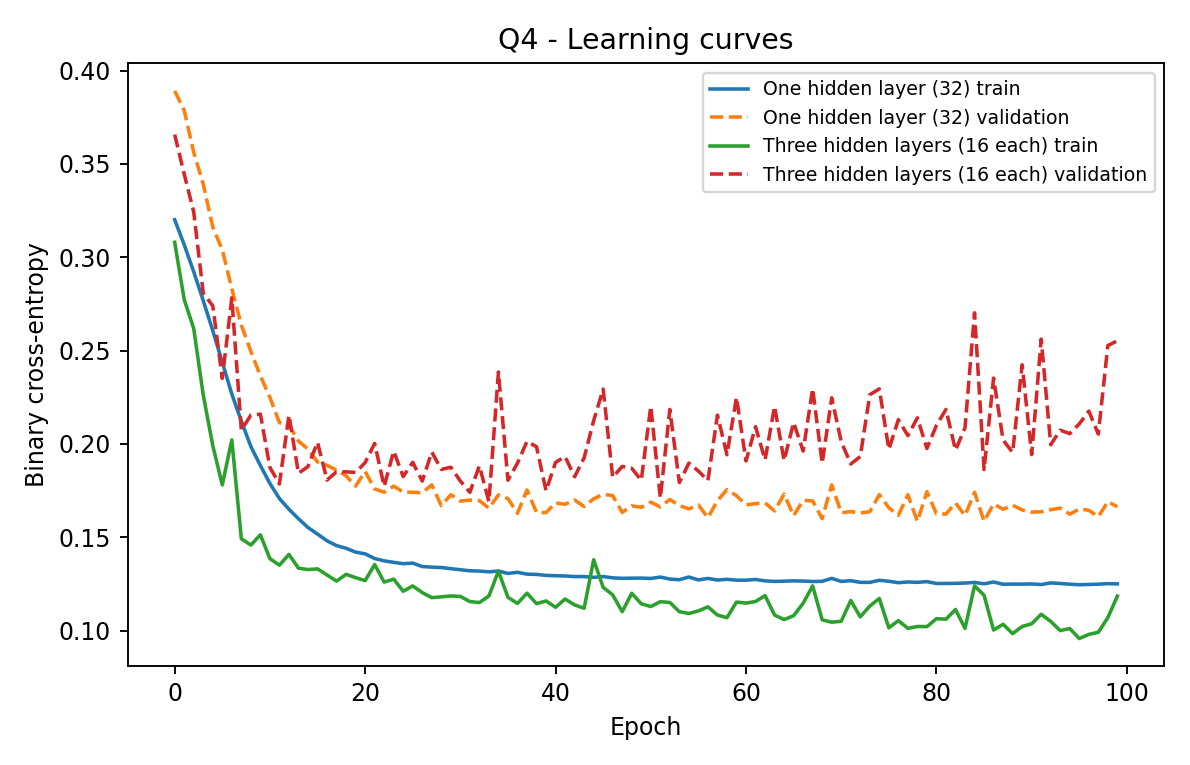

q5_accuracy.png


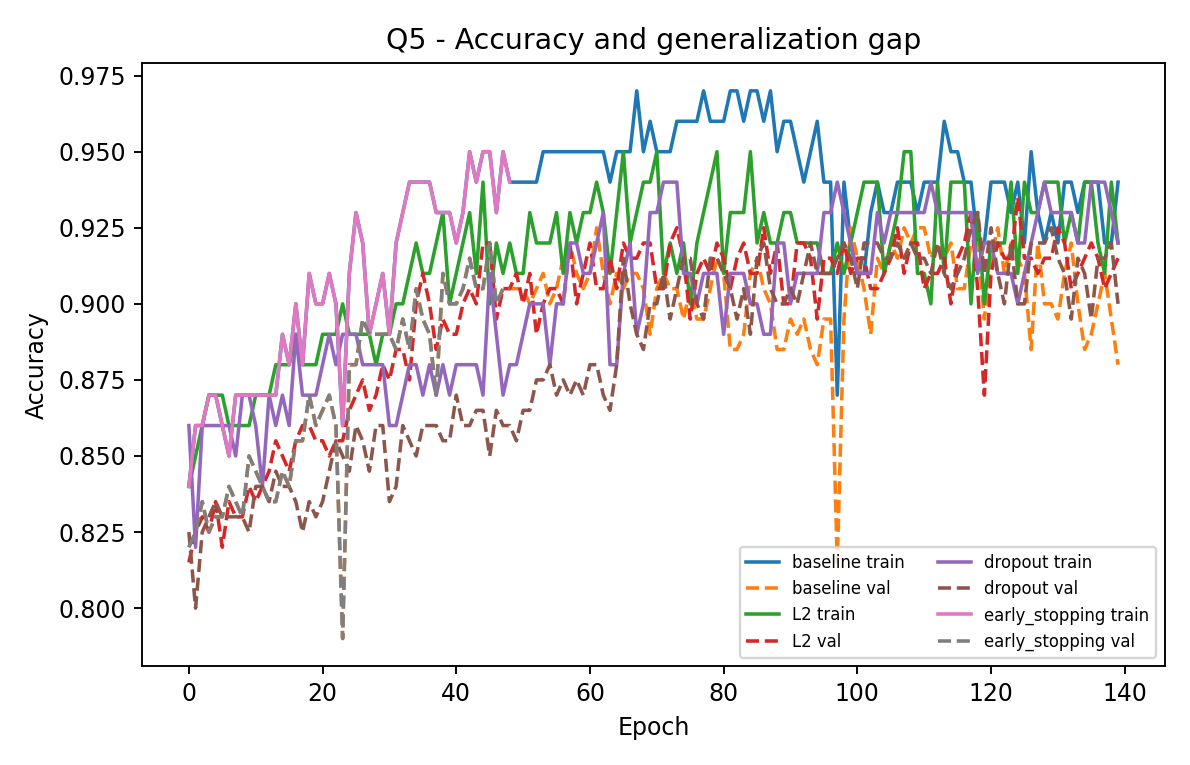

q5_regularization.png


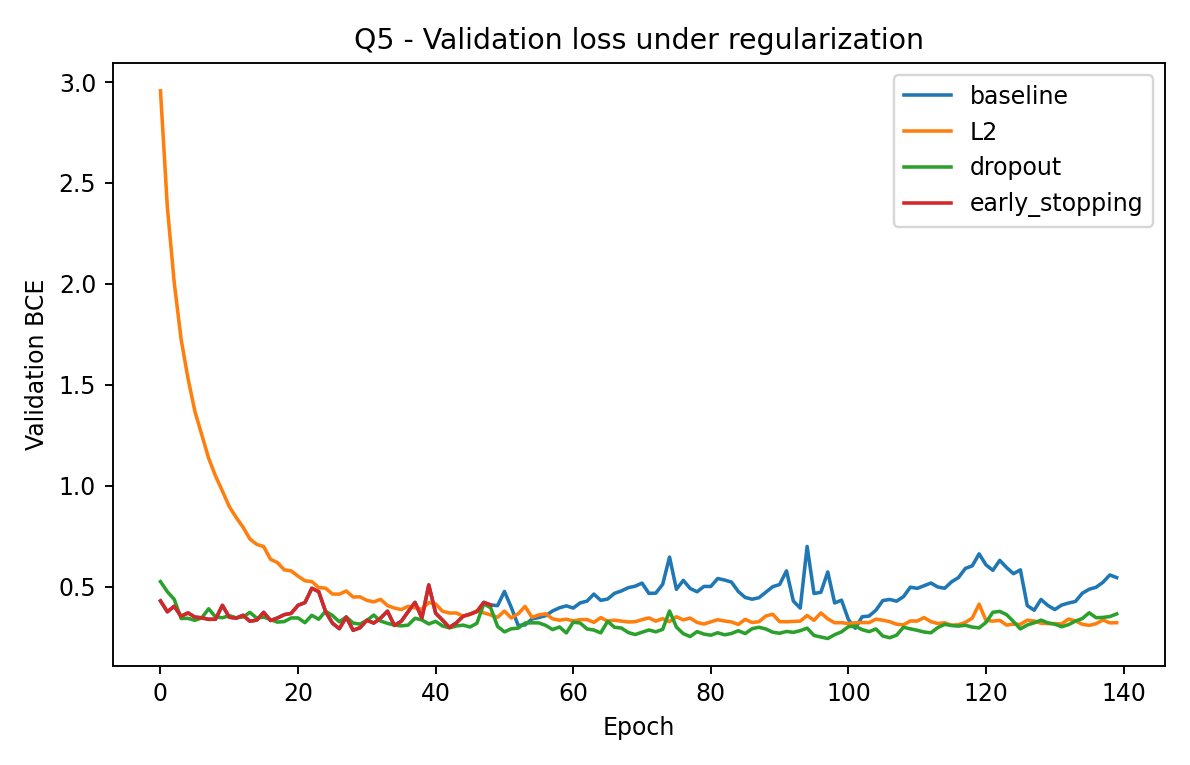

q6_validation_loss.png


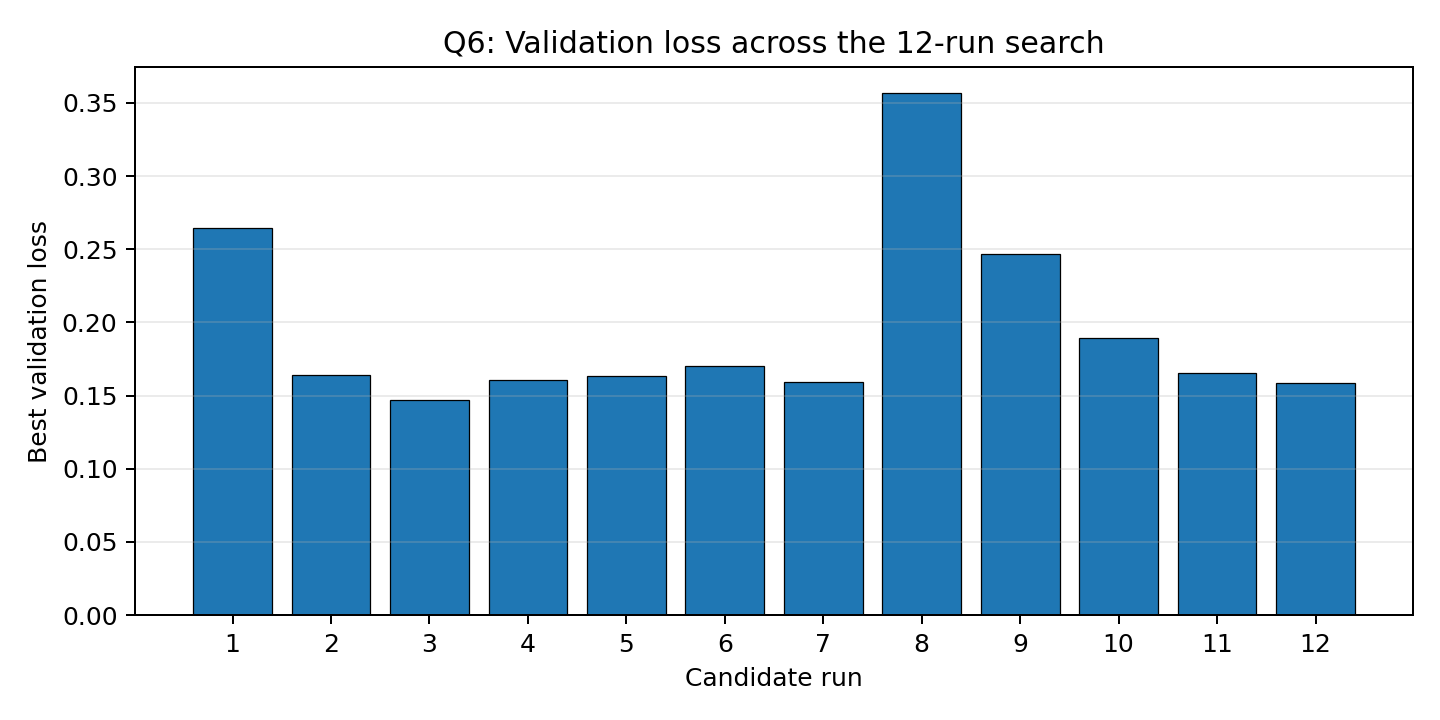

q7_redesign_workflow.png


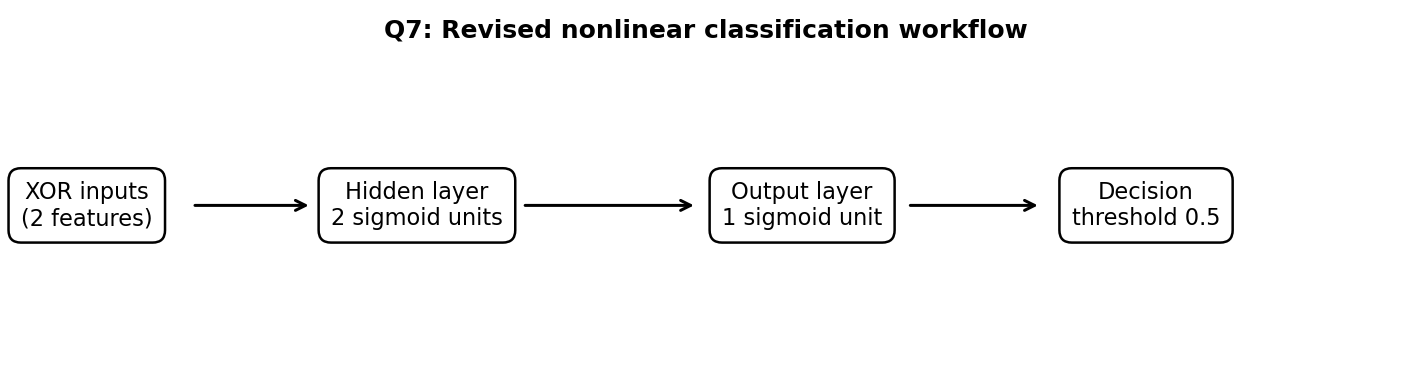

In [12]:
print('Q1 parameter counts:', q1['linear']['parameters'], 'and', q1['hidden']['parameters'])
print('Q2 AND:', q2_and['converged'], q2_and['epochs_run'], q2_and['predictions_final'])
print('Q2 XOR:', {lr: (v['converged'], v['predictions_final']) for lr,v in q2_xor.items()})
print('Q3 finite-difference gradient check:', q3_fd)
print('Q3 XOR MLP accuracy/loss:', q3_xor['accuracy'], q3_xor['final_loss'])
print('Q4 architecture selected on validation loss:', q4_selected)
print('Q5 regularizer selected on validation loss:', q5_selected)
print('Q6 selected configuration:', q6_selected)
print('Q7 perceptron vs MLP accuracy:', 0.5, q7['redesigned_mlp']['accuracy'])

results_table=pd.DataFrame([
 {'Question':'Q4 selected architecture','Validation loss':q4_selected['mean_validation_loss'],'Validation accuracy':q4[q4_selected['architecture']]['val_accuracy_mean'],'Test accuracy':q4_selected['test_accuracy_mean']},
 {'Question':'Q5 selected regularizer','Validation loss':q5_selected['validation_loss'],'Validation accuracy':q5_selected['validation_accuracy'],'Test accuracy':q5_selected['test_accuracy']},
 {'Question':'Q6 selected optimizer config','Validation loss':q6_selected['best_validation_loss'],'Validation accuracy':q6_selected['best_validation_accuracy'],'Test accuracy':q6_selected['final_test_accuracy']}
])
display(results_table)

from IPython.display import display, Image
for filename in sorted(os.listdir(FIG)):
    if filename.endswith('.png'):
        print(filename)
        display(Image(filename=os.path.join(FIG,filename)))